**Innovation Management · A.Y. 2026/27 · Politecnico di Torino** · Tutorial 1, notebook 2 of 2

| | |
|---|---|
| **Goal** | Answer the Step 2 questions of the PW (competitive landscape): measure how concentrated your sector is, who the incumbents and the entrants are, which subfields grow, and which forces shape it. |
| **Before this** | 10 · Patent attributes; Step 1 of the PW |
| **Time** | 90 min |
| **PATSTAT environment** | PROD (the tables saved by Step 0; one query in Section 5.0) |

← [10 · Patent attributes](10_patent_attributes.ipynb) &nbsp;|&nbsp; [Back to the README](../README.md)

<sub>Adapted from the EPO TIP training materials (https://github.com/epo/tip-training). This version has been modified and is not authorised by the EPO; the EPO is not responsible for its correctness. Section 3 uses the six measures of Liston-Heyes, C. & Pilkington, A. (2004), Inventive concentration in the production of green technology: a comparative analysis of fuel cell patents, Science and Public Policy, 31(1), 15–25, available in the academic_papers folder.</sub>

# Step 2 of the PW: Competitive landscape

| Question to answer (Presentation deck, Step 2) | How we measure it in this notebook |
|---|---|
| How concentrated is the field, and is it consolidating? | Six measures of concentration from the literature (Sections 3–4); the Herfindahl index and the 4-firm ratio over time (Section 5.1) |
| Who are the incumbents, and who are the new entrants? | Top applicants with type and country; new applicants per year, their share of families, and the rate of disappearance; who cites whom among the top applicants (Section 5.2) |
| Which subfields are growing fastest? | Growth of the CPC groups of the sector between two periods (Section 5.3) |
| Which political, economic, social and technological forces shape it? | PEST analysis of the political, economic, social and technological forces, with sources outside PATSTAT (Section 5.4) |


**Contents**
1. Setup and configuration
2. The unit of analysis: applicants, and how Step 0 consolidated their names
3. Proxies for concentration: six measures from the literature
4. Example: inventive concentration in fuel cells (not used in this project)
5. Answering the Step 2 questions for humanoid robots

## 1. Setup and configuration

In [1]:
import json
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy import stats                      # linear regression (Lotka)
from sqlalchemy import func

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,               # applications
    TLS206_PERSON,              # persons: names, sector, country
    TLS207_PERS_APPLN,          # person <-> application links (applicant / inventor)
)

In [2]:
# ---------------------------------------------------------------- environment
ENV = "PROD"                                       # the tables that Step 0 saved on PROD (on TEST the numbers mean nothing)
DATA_DIR = Path("..") / "tutorial_0" / "data" / ENV / "humanoid_robots_v2"   # written by Step 0 v2, Section 7
OUTPUT_DIR = Path("outputs/step2")                 # name this how you wish
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- your sector
SECTOR_NAME = "Humanoid robots"                    # the families are the ones kept by the sector rules of Step 0: no CPC prefixes here

# ---------------------------------------------------------------- time window: we read it from Step 0, so the notebooks always agree
meta = json.loads((DATA_DIR / "dataset_metadata.json").read_text())
YEAR_MIN, YEAR_MAX = meta["window"]                # 2000-2025, earliest priority year of the family
LAST_COMPLETE_YEAR = meta["last_complete_year"]    # the same year that Step 0 used to flag the truncated families

# ---------------------------------------------------------------- our choices for Step 2
SPLIT_YEAR = 2015                    # incumbents file their first family before SPLIT_YEAR, entrants from SPLIT_YEAR on
WINDOW = 3                           # years per window when following concentration over time
MIN_WINDOW_FAMILIES = 30             # we plot a window only if it has this many families: with fewer, HH only says how few applicants there are
PLOT_FROM = 2000                     # entry and exit are plotted from this year: before, the sector is too small (same base year as Step 1)
YOUNG_FIRM_YEAR = 2010               # a firm whose first patent ever is from this year on is a "young firm": our proxy for a start-up
TOP_N = 15                           # rows in the tables of top applicants
MIN_SUBFIELD = 15                    # a subfield needs this many families in the last 5 complete years to be on the map
MIN_PAST = 5                         # ...and this many in the 5 years before to get a growth rate: from a base of one or two families, +1000% means nothing

print(f"Sector: {SECTOR_NAME} | env: {ENV} | years {YEAR_MIN}-{YEAR_MAX} | complete years up to {LAST_COMPLETE_YEAR}")

Sector: Humanoid robots | env: PROD | years 2000-2025 | complete years up to 2022


In [3]:
patstat = PatstatClient(env=ENV)
db = patstat.orm()

## 2. The unit of analysis: applicants

In Step 1 we counted **families** and **applications**. Concentration needs one more unit: the **applicant**, the owner of the patent. We must decide when two names on two patents are **the same applicant**.

### 2.1 The "name game"

The same company appears in PATSTAT under many spellings (*SIEMENS AG*, *Siemens Aktiengesellschaft*, *SIEMENS AKTIENGESELLSCHAFT MUENCHEN*…). If we count each spelling as a different firm, a large firm is split into many small ones and **every concentration measure is wrong**. `tls206_person` offers:

| Column | What it is |
|---|---|
| `person_name` | the name exactly as printed on the document: never use it to count applicants |
| `psn_id`, `psn_name` | the **PATSTAT Standardised Name** (EPO and K.U. Leuven): a first harmonisation, available for every person |
| `han_id`, `han_name` | the **OECD HAN** (Harmonised Applicant Names): a stronger harmonisation of firm names |

`psn_name` is a good start, but it still leaves variants (*TOYOTA JIDOSHA KK* and *TOYOTA MOTOR CORP*, with and without legal forms…), and it never merges a subsidiary with its parent.

### 2.2 How Step 0 consolidated the names

We do not consolidate the names again: Step 0 (v2, Section 7.2) did it and saved the result. In short:

1. for each person record, the best name: the OECD HAN name if it was harmonised, otherwise the PSN name, otherwise the name standardised from the document, otherwise the name as printed (`name_source`);
2. the legal forms are removed and the name is normalised, also for full-width characters and abbreviations with dots (`applicant_norm`);
3. the **brand key** groups the names of one organisation (`applicant`): for firms, the first distinctive word after the place names that open Chinese names, two words when the first is generic; universities, institutes and individuals keep their whole name; three certain aliases (UBTECH and its Chinese name, Unitree and Hangzhou Yushu, Aldebaran and SoftBank Robotics Europe). Each applicant is shown with its most frequent full name. The applicant is the owner named on the patent: Boston Dynamics stays apart from Google and Hyundai.

On the gold standard of the course (Section 2.4 of the tutorial: 3,192 names of 481 organisations) the brand key reaches a pairwise F1 of 0.918 (precision 0.964, recall 0.876), against 0.005 for the legal-form dictionary alone. Section 5.1 shows how much the choice of names changes the concentration.

### 2.3 From the tables of Step 0 to applicants

Step 0 saved one row per family and applicant (`family_applicants`). We add to each applicant:

- **`type`**: firm, university, individual… from `psn_sector` (the column mixes several labels, so we map it to a few types). An applicant has one type: the most frequent among its records, ignoring the records without a type;
- **`ctry`**: the applicant's country. A firm can have different countries on different patents (or none): we give each applicant the country that appears **most often** among its records. If an applicant has no known country at all, we use the office of first filing of its families, the same rule as Step 1 (section 9.2).

In [4]:
# names of universities, institutes, labs and hospitals (the same words as Step 0, Section 7.2)
INSTITUTION_PATTERN = r"\b(?:UNIV\w*|INST\w*|ACADEM\w*|COLLEGE|SCHOOL|HOSPITAL|LAB\w*|CENT(?:ER|RE)|DAXUE|XUEYUAN)\b"
def applicant_type(psn_sector):
    "Translate the PATSTAT psn_sector into the types used in the deck."
    s = str(psn_sector).upper()
    if "UNIVERSITY" in s:
        return "university"
    if "COMPANY" in s:
        return "firm"
    if "GOV" in s:
        return "government / non-profit"
    if "HOSPITAL" in s:
        return "hospital"
    if "INDIVIDUAL" in s:
        return "individual"
    return "unknown"


def first_filing_offices(applications):
    "One row per (family, office of first filing), as in Step 1: the office of the earliest filing date, WO excluded."
    a = applications.loc[applications["appln_auth"] != "WO", ["docdb_family_id", "appln_auth", "appln_filing_date"]].copy()
    d = pd.to_datetime(a["appln_filing_date"], errors="coerce")
    a["filing_date"] = d.where(d.dt.year < 9000)                 # 9999-12-31 is a placeholder
    first = a[a["filing_date"] == a.groupby("docdb_family_id")["filing_date"].transform("min")]
    first = first.drop_duplicates(["docdb_family_id", "appln_auth"]).rename(columns={"appln_auth": "country"})
    return first[["docdb_family_id", "country"]]


def prepare_applicants(fa, families, applications):
    "From the Step 0 tables to one row per (family, applicant), with the year, one type and one country per applicant."
    df = fa.merge(families[["docdb_family_id", "priority_year"]], on="docdb_family_id")
    df = df.rename(columns={"docdb_family_id": "unit_id", "priority_year": "year"})

    # 1. the type of applicant: the most frequent known type among its records
    df["type"] = df["applicant_type"].map(applicant_type)
    known_type = df[df["type"] != "unknown"].groupby("applicant")["type"].agg(lambda t: t.value_counts().index[0])
    df["type"] = df["applicant"].map(known_type).fillna("unknown")
    # PATSTAT gives no type to many recent filers: a name without university or institute words is read as a firm
    no_type = df["type"].eq("unknown") & ~df["applicant"].str.contains(INSTITUTION_PATTERN, regex=True)
    df.loc[no_type, "type"] = "firm"

    # 2. one country per applicant: the most frequent known one; if it has none, the most frequent office of first filing of its families
    df["country"] = df["country"].fillna("").str.strip()
    main_country = df[df["country"] != ""].groupby("applicant")["country"].agg(lambda c: c.value_counts().index[0])
    office = first_filing_offices(applications).drop_duplicates("docdb_family_id").rename(columns={"docdb_family_id": "unit_id", "country": "office"})
    main_office = (df.merge(office, on="unit_id").groupby("applicant")["office"].agg(lambda c: c.value_counts().index[0]))
    df["ctry"] = df["applicant"].map(main_country)
    df["country_from_office"] = df["ctry"].isna()                  # True when the country is the office of first filing
    df["ctry"] = df["ctry"].fillna(df["applicant"].map(main_office)).fillna("")

    return df[["unit_id", "year", "applicant", "type", "ctry", "country_from_office", "weight"]].drop_duplicates(["unit_id", "applicant"])

## 3. Proxies for concentration: six measures from the literature

**What we want to know.** Are the inventions of the sector produced by a **few** applicants, or spread over **many**? A concentrated field is dominated by a handful of players; a dispersed field has many inventors of similar size, and it is easier to enter.

**Patents, not market shares.** In industrial economics, concentration is measured with **market shares**: the share of sales held by the largest firms. We do not observe sales. We use **patent data** and measure the share of the **patents (or families)** held by each applicant. This is **inventive concentration**: it tells who controls the production of new technology, which can differ from who controls the market today.

**Two levels of analysis.**

- **The whole sector**: one value of each measure for all the applicants of the sector, and how it changes over time. This is what we do for your sector in Section 5.1.
- **Country by country**: the same measures computed separately on the applicants of each country, to compare countries. This is what the paper does, and we do it in Section 5.1 for the countries of our applicants.

The six measures below are those used by **Liston-Heyes, C. & Pilkington, A. (2004), *Inventive concentration in the production of green technology: a comparative analysis of fuel cell patents*, Science and Public Policy, 31(1), 15–25**. The paper is available in the **academic_papers** folder.

Let $x_i$ be the number of patents of firm $i$, $N$ the number of firms, and $s_i = x_i / \sum_j x_j$ the share of firm $i$, with the firms sorted from the largest.

| Measure | Formula | What it says |
|---|---|---|
| **4-firm and 8-firm concentration ratio** | $CR_k = \sum_{i=1}^{k} s_i$ | the share of patents of the $k$ largest firms; simple, but it ignores all the other firms |
| **Herfindahl index** | $HH = \sum_{i=1}^{N} s_i^2$ | sum of squared shares: 1 if one firm has all the patents, $1/N$ if all firms have the same number |
| **Numbers-equivalent** | $1/HH$ | the number of firms of *equal size* that would give the same $HH$ |
| **Coefficient of variation** | $CV = \sigma_x / \bar{x}$ | the standard deviation of patents per firm divided by their mean: how different the firms are, whatever their size |
| **Gini coefficient** | from the Lorenz curve (below) | 0 if all firms have the same number of patents, close to 1 if one firm has almost all of them |
| **Lotka coefficient** | slope $L$ of the line $\log f(n) = c + L \log n$ | $f(n)$ is the number of firms with exactly $n$ patents. Lotka's law of scientific productivity predicts $L = -2$; the closer $L$ is to 0, the more firms with many patents, so the more concentrated |

The **Lorenz curve** sorts the firms from the smallest to the largest and plots the cumulative share of firms (x) against the cumulative share of patents (y). With equal firms it is the diagonal; the more concentrated the patents, the further it bends below. The **Gini coefficient** is the area between the diagonal and the curve, divided by the whole area below the diagonal.

Each function below computes one measure from `patents_per_firm`, a list with the number of patents of each firm.

In [5]:
def concentration_ratio(patents_per_firm, k):
    "Share (%) of all patents held by the k largest firms."
    largest_first = np.sort(patents_per_firm)[::-1]
    return largest_first[:k].sum() / largest_first.sum() * 100


def herfindahl(patents_per_firm):
    "Sum of the squared shares of the firms."
    shares = np.asarray(patents_per_firm) / np.sum(patents_per_firm)
    return np.sum(shares ** 2)


def coefficient_of_variation(patents_per_firm):
    "Standard deviation of patents per firm divided by their mean."
    x = np.asarray(patents_per_firm, dtype=float)
    return x.std(ddof=1) / x.mean()


def lorenz_curve(patents_per_firm):
    "Cumulative share of firms (smallest first) and cumulative share of their patents."
    x = np.sort(patents_per_firm)                     # smallest firms first
    share_of_firms = np.arange(0, len(x) + 1) / len(x)
    share_of_patents = np.concatenate([[0], np.cumsum(x) / x.sum()])
    return share_of_firms, share_of_patents


def gini(patents_per_firm):
    "Area between the diagonal and the Lorenz curve, divided by the area below the diagonal (= 0.5)."
    share_of_firms, share_of_patents = lorenz_curve(patents_per_firm)
    # area below the Lorenz curve, as a sum of trapezoids
    widths = np.diff(share_of_firms)
    heights = (share_of_patents[1:] + share_of_patents[:-1]) / 2
    area_below_curve = np.sum(widths * heights)
    return (0.5 - area_below_curve) / 0.5


def lotka(patents_per_firm):
    "Slope (and its p-value) of log(number of firms with n patents) on log(n)."
    f = pd.Series(patents_per_firm).value_counts().sort_index()   # n -> number of firms with n patents
    if len(f) < 3:                                                 # too few points to fit a line
        return np.nan, np.nan
    fit = stats.linregress(np.log(f.index), np.log(f.values))
    return fit.slope, fit.pvalue


def six_measures(patents_per_firm):
    "All the measures for one group of firms, as one row of a table."
    lotka_slope, lotka_pvalue = lotka(patents_per_firm)
    return {
        "firms": len(patents_per_firm),
        "patents (sum over firms)": int(np.sum(patents_per_firm)),
        "CV": coefficient_of_variation(patents_per_firm),
        "CR4 (%)": concentration_ratio(patents_per_firm, 4),
        "CR8 (%)": concentration_ratio(patents_per_firm, 8),
        "HH": herfindahl(patents_per_firm),
        "1/HH": 1 / herfindahl(patents_per_firm),
        "Lotka L": lotka_slope,
        "Lotka p-value": lotka_pvalue,
        "Gini": gini(patents_per_firm),
    }


# A quick check on two toy sectors: 10 equal firms, and one giant with 9 small firms
pd.DataFrame({"10 equal firms": six_measures([5] * 10),
              "1 giant + 9 small": six_measures([91] + [1] * 9)}).round(3)

,10 equal firms,1 giant + 9 small
firms,10.0,10.000
patents (sum over firms),50.0,100.000
CV,0.0,2.846
CR4 (%),40.0,94.000
CR8 (%),80.0,98.000
HH,0.1,0.829
1/HH,10.0,1.206
Lotka L,NaN,NaN
Lotka p-value,NaN,NaN
Gini,0.0,0.810


In the toy example, the equal sector has $HH = 1/10$, a numbers-equivalent of 10, CV and Gini equal to 0, and no Lotka line (all firms have the same $n$). In the sector with one giant, the four largest firms hold 94% of the patents and the Gini is close to 0.8.

## 4. Example: inventive concentration in fuel cells (Liston-Heyes & Pilkington, 2004)

We do not use this section: it replicates the paper on the US fuel-cell patents, which are not our sector. What we keep of it we do in Section 5.1 on humanoid robots: the six measures of Section 3 country by country, as the paper does, and the comparison of the measures with Kendall's tau-b (the paper does it on the ranking of the countries, here we do it on time windows).

---

## 5. Answering the Step 2 questions for humanoid robots

We answer the four questions of Step 2 for our sector: the **families** that Step 0 kept, filed anywhere in the world and dated by their earliest priority year, from `YEAR_MIN` to `YEAR_MAX`. The complete years are those up to `LAST_COMPLETE_YEAR`; the grey areas of the figures are the incomplete ones.

### 5.0 Data: the sector's families, their applicants and their CPC codes

In [6]:
def answer_box(question, headline, detail=""):
    "Print the answer to one question of the deck, built from the numbers above (plain text, so that it also survives the PDF export)."
    print("-" * 80)
    print(f"ANSWER · {question}")
    for text in (headline, detail):
        if text:
            print(textwrap.fill(text, width=80))
    print("-" * 80)


def load_table(name):
    """A table saved by Step 0: parquet, or pickle if pyarrow was missing there."""
    for suffix, reader in ((".parquet", pd.read_parquet), (".pkl", pd.read_pickle)):
        if (DATA_DIR / f"{name}{suffix}").exists():
            return reader(DATA_DIR / f"{name}{suffix}")
    raise FileNotFoundError(f"{name} is not in {DATA_DIR}: run Step 0 (section 5.12) on {ENV} first")


families = load_table("families")                      # one row per family of the sector
applications = load_table("applications")              # one row per application of those families (we use it for the office of first filing)
family_applicants = load_table("family_applicants_grouped")   # one row per family and applicant, consolidated by Step 0 v2 (Section 7.2)     
applicant_names = load_table("applicant_names")        # one row per name as printed in PATSTAT, with the applicant it was merged into
family_cpc = load_table("family_cpc")                  # the CPC symbols of the families
family_ipc = load_table("family_ipc")                  # the IPC symbols, for the families without CPC (Section 5.3)
family_citations = load_table("family_citations")      # citations between the families of the sector and all the other families

families = families[families["priority_year"].between(YEAR_MIN, YEAR_MAX)].copy()
links = prepare_applicants(family_applicants, families, applications)      # year = earliest priority year of the family

n_without = families["docdb_family_id"].nunique() - links["unit_id"].nunique()
print(f"{SECTOR_NAME}: {len(families):,} families, {links['unit_id'].nunique():,} with at least one applicant ({n_without:,} without)")
one_per_applicant = links.drop_duplicates("applicant")
print(f"{len(one_per_applicant):,} applicants by type: {one_per_applicant['type'].value_counts().to_dict()}")
print(f"country taken from the office of first filing for {one_per_applicant['country_from_office'].sum():,} applicants "
      f"(they have no known country in PATSTAT)")

Humanoid robots: 2,907 families, 2,895 with at least one applicant (12 without)
1,239 applicants by type: {'firm': 626, 'individual': 271, 'university': 239, 'unknown': 60, 'government / non-profit': 42, 'hospital': 1}
country taken from the office of first filing for 857 applicants (they have no known country in PATSTAT)


**First patent ever.** The applicants that are **new to the sector** we find in our families. The ones that are **new to patenting** (they never patented before, the wording of the Step 2 slide) need the first patent of each applicant in any field: this is the only query of this notebook.

Step 0 did not keep the `psn_id` of the persons, so we look the names up in `tls206_person`. Step 0 took the name of each person from one of four columns (HAN, PSN, name standardised from the document, name as printed) and did not save which one, so we search the four columns and keep the earliest year. The result is saved in `outputs/step2/first_patent_year.csv`: the next runs read the file and query only the names that are not in it.

Two limits. Every name of Step 0 comes from PATSTAT, so each one is found, and the lookup cannot tell one person from another with the same name: a common name (many individuals) can pick up the patents of other persons and look older than it is. And a firm that patented before under another spelling or another legal name looks newer than it is: the harmonised names of PATSTAT are not updated for the latest years. So "new to patenting" is an approximation and we read its shares as orders of magnitude.

In [7]:
# The first patent ever (in any field) of each applicant, to identify newcomers to patenting.
# Step 0 took the name of each person from one of four columns of tls206 (name_source), but it did not keep which one for each name:
# we look every name up in the four columns and keep the earliest year found
NAME_COLUMNS = {"han_name": TLS206_PERSON.han_name, "psn_name": TLS206_PERSON.psn_name,
                "doc_std_name": TLS206_PERSON.doc_std_name, "person_name": TLS206_PERSON.person_name}
FIRST_PATENT_FILE = OUTPUT_DIR / "first_patent_year.csv"      # saved, so that the long query runs only once


def first_patent_by_name(names, column, chunk=1000):
    "For each name found in `column` of tls206: the earliest priority year of an application where it is an applicant."
    col = NAME_COLUMNS[column]
    found = []
    for start in range(0, len(names), chunk):                  # in chunks, to keep each query small
        q_first = (
            db.query(col.label("name_raw"), func.min(TLS201_APPLN.earliest_filing_year).label("first_patent_year"))
            .select_from(TLS206_PERSON)
            .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
            .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id)
            .filter(col.in_(names[start:start + chunk]),
                    TLS207_PERS_APPLN.applt_seq_nr > 0,                                        # applicants only
                    TLS201_APPLN.appln_id > 0, TLS201_APPLN.appln_id < 900_000_000,            # real applications, as in Step 0
                    TLS201_APPLN.earliest_filing_year.between(1900, YEAR_MAX))                 # drops the 9999 placeholders
            .group_by(col)
        )
        out = patstat.df(q_first)
        if len(out):                                           # a query without rows comes back without columns
            found.append(out)
    return pd.concat(found, ignore_index=True) if found else pd.DataFrame(columns=["name_raw", "first_patent_year"])


names = applicant_names["name_raw"].dropna().unique().tolist()
if FIRST_PATENT_FILE.exists():
    first_by_name = pd.read_csv(FIRST_PATENT_FILE, index_col="name_raw")["first_patent_year"]
else:
    first_by_name = pd.Series(dtype=float, name="first_patent_year", index=pd.Index([], name="name_raw"))

todo = [n for n in names if n not in first_by_name.index]
if todo:
    looked_up = pd.concat([first_patent_by_name(todo, column) for column in NAME_COLUMNS], ignore_index=True)
    looked_up = looked_up.groupby("name_raw")["first_patent_year"].min().reindex(todo)      # NaN: no person has this name
    first_by_name = looked_up if first_by_name.empty else pd.concat([first_by_name, looked_up])
    first_by_name.to_csv(FIRST_PATENT_FILE)
print(f"{len(names):,} names; looked up now: {len(todo):,}; found in PATSTAT: {first_by_name.reindex(names).notna().sum():,}")

1,412 names; looked up now: 0; found in PATSTAT: 1,412


In [8]:
# the first patent ever of each consolidated applicant: the earliest among the names it groups
name_to_applicant = applicant_names.drop_duplicates("name_raw").set_index("name_raw")["applicant"]
found = first_by_name.dropna().rename("first_patent_year").reset_index()
found["applicant"] = found["name_raw"].map(name_to_applicant)
first_ever = found.dropna(subset=["applicant"]).groupby("applicant")["first_patent_year"].min()

# the families of the sector are patents too: the first patent ever cannot be later than the first family in the sector
first_in_sector = links.groupby("applicant")["year"].min().reindex(first_ever.index)
n_later = int((first_ever > first_in_sector).sum())
first_ever = first_ever.clip(upper=first_in_sector)

n_app = links["applicant"].nunique()
print(f"first patent ever found for {len(first_ever):,} of {n_app:,} applicants ({len(first_ever) / n_app:.0%}); "
      f"{n_later} were later than their first family in the sector and we set them to that year")


first patent ever found for 1,239 of 1,239 applicants (100%); 0 were later than their first family in the sector and we set them to that year


### 5.1 Question: how concentrated is the field, and is it consolidating?

First the six measures of Section 3 on the whole sector in the complete years, with **families** in place of patents. We compute them on **all applicants** and on **firms only**: the paper counts firms only, but in our sector universities hold a large share of the families (Step 1, section 10.1). In this table `firms` means applicants: in the first column it counts universities too.

In [9]:
complete = links[links["year"] <= LAST_COMPLETE_YEAR]
families_per_applicant = complete.groupby("applicant")["unit_id"].nunique()
families_per_firm = complete[complete["type"] == "firm"].groupby("applicant")["unit_id"].nunique()

pd.DataFrame({"all applicants": six_measures(families_per_applicant.to_numpy()),
              "firms only": six_measures(families_per_firm.to_numpy())}).round(3)

,all applicants,firms only
firms,724.000,240.000
patents (sum over firms),1705.000,589.000
CV,2.107,2.357
CR4 (%),12.493,27.334
CR8 (%),18.710,37.521
HH,0.008,0.027
1/HH,133.209,36.731
Lotka L,-1.436,-1.125
Lotka p-value,0.000,0.000
Gini,0.500,0.533


**Do the names matter?** The lecture on the name game warns that, without entity linking, we can underestimate how concentrated a sector is. The table shows it with our data: the same measures with four definitions of "applicant", from the name of PATSTAT (A) to the coarse key of Step 0 (D), which merges firms whose distinctive word is generic. C is the main version of the project. If D is much more concentrated than C, the answer depends on how far we merge names; for the deck we show both.

**How are the families shared?** Two figures of the paper on our sector (Section 4.6 of the tutorial). The Lorenz curve sorts the applicants from the smallest to the largest: read a point as "the smallest *x*% of the applicants hold *y*% of the families"; the further it bends below the diagonal, the more concentrated the sector. Lotka's law says that if f(1) applicants have one family, about f(1)/n² have n families (a slope of −2 on log-log axes): a flatter fitted line means more applicants with many families than the law predicts, i.e. a more concentrated sector.

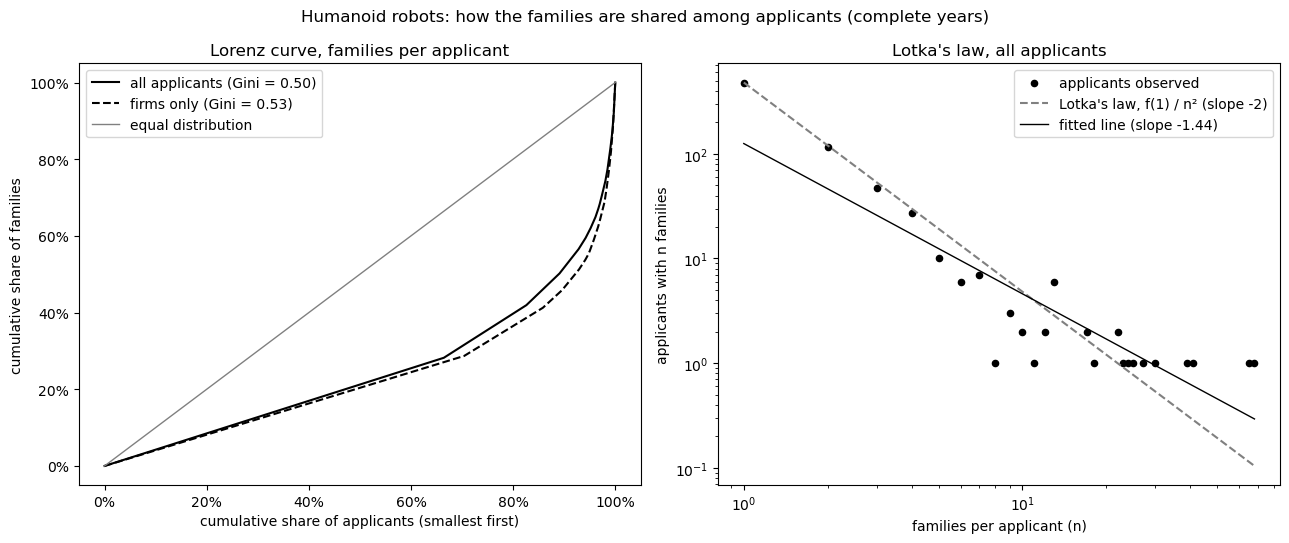

,applicants observed,applicants predicted (f(1) / n²)
families per applicant (n),,
1,481,481.0
2,117,120.2
3,47,53.4
4,27,30.1
5,10,19.2
6,6,13.4
7,7,9.8
8,1,7.5
9,3,5.9


In [10]:
# Lorenz curve of our sector (the paper's Figure 1): all applicants and firms only, complete years
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for label, x, style in [("all applicants", families_per_applicant.to_numpy(), "-"),
                        ("firms only", families_per_firm.to_numpy(), "--")]:
    share_of_applicants, share_of_families = lorenz_curve(x)
    axes[0].plot(share_of_applicants, share_of_families, color="black", ls=style, label=f"{label} (Gini = {gini(x):.2f})")
axes[0].plot([0, 1], [0, 1], color="grey", lw=1, label="equal distribution")
axes[0].set(title="Lorenz curve, families per applicant", xlabel="cumulative share of applicants (smallest first)",
            ylabel="cumulative share of families")
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend()

# Lotka's law: number of applicants with n families, observed and predicted by f(1) / n^2, on log-log axes
observed = pd.Series(families_per_applicant.to_numpy()).value_counts().sort_index()
n = observed.index.to_numpy()
fit = stats.linregress(np.log(n), np.log(observed.to_numpy()))
axes[1].scatter(n, observed, color="black", s=20, label="applicants observed")
axes[1].plot(n, observed.get(1, 0) / n ** 2, color="grey", ls="--", label="Lotka's law, f(1) / n² (slope -2)")
axes[1].plot(n, np.exp(fit.intercept) * n ** fit.slope, color="black", lw=1, label=f"fitted line (slope {fit.slope:.2f})")
axes[1].set(xscale="log", yscale="log", title="Lotka's law, all applicants",
            xlabel="families per applicant (n)", ylabel="applicants with n families")
axes[1].legend()
fig.suptitle(f"{SECTOR_NAME}: how the families are shared among applicants (complete years)")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "lorenz_lotka.png", dpi=200, bbox_inches="tight")
plt.show()

lotka_check = pd.DataFrame({"applicants observed": observed,
                            "applicants predicted (f(1) / n²)": observed.get(1, 0) / n ** 2})
lotka_check.index.name = "families per applicant (n)"
lotka_check.head(10).round(1)

In [13]:
# How much do the names matter? The same measures with four definitions of "applicant" (all years, all types).
# applicant_names has one row per family and name: for each definition we count the DIFFERENT families of each applicant,
# so a family that carries two spellings of one applicant counts once.
definitions = {"A. PATSTAT name as it is": "name_raw",
               "B. + legal forms removed": "applicant_norm",
               "C. + brand key and aliases (main version)": "applicant",
               "D. coarse key": "applicant_auto",
              }
sensitivity = pd.DataFrame({label: six_measures(applicant_names.groupby(column)["docdb_family_id"].nunique().to_numpy())
                            for label, column in definitions.items()}).T
sensitivity[["firms", "CR4 (%)", "CR8 (%)", "HH", "1/HH", "Gini"]].rename(columns={"firms": "applicants"}).round(3)

,applicants,CR4 (%),CR8 (%),HH,1/HH,Gini
A. PATSTAT name as it is,1412.0,9.401,14.823,0.005,209.307,0.535
B. + legal forms removed,1308.0,10.268,16.600,0.006,181.652,0.544
C. + brand key and aliases (main version),1239.0,10.678,17.190,0.006,170.373,0.551
D. coarse key,1235.0,10.736,17.248,0.006,169.453,0.552
E. Terrorizer,991.0,14.498,23.512,0.010,99.529,0.628


A field is **consolidating** when **fewer applicants account for more of the inventions over time**. We compute HH, its numbers-equivalent (1/HH) and CR4 on windows of `WINDOW` consecutive years (one year alone is often too small): an increasing HH and CR4, and a decreasing 1/HH, mean consolidation. We plot only the windows with at least MIN_WINDOW_FAMILIES families, for all applicants and for firms only; the grey area marks the windows that end in an incomplete year.

In [14]:
def windowed_measures(links_, width):
    "HH, 1/HH and CR4 on windows of `width` consecutive years (families per applicant), labelled with the last year of the window."
    rows = []
    for end in range(YEAR_MIN + width - 1, YEAR_MAX + 1):
        window = links_[links_["year"].between(end - width + 1, end)]
        x = window.groupby("applicant")["unit_id"].nunique().to_numpy()
        if len(x) < 2:
            continue
        rows.append({"window end": end, "families": window["unit_id"].nunique(), "applicants": len(x),
                     "HH": herfindahl(x), "1/HH": 1 / herfindahl(x), "CR4 (%)": concentration_ratio(x, 4)})
    return pd.DataFrame(rows).set_index("window end")


over_time = {"all applicants": windowed_measures(links, WINDOW),
             "firms only": windowed_measures(links[links["type"] == "firm"], WINDOW)}
over_time = {label: t[t["families"] >= MIN_WINDOW_FAMILIES] for label, t in over_time.items()}     # windows too small are left out

table_windows = over_time["all applicants"].assign(provisional=lambda t: t.index > LAST_COMPLETE_YEAR)
table_windows.round(3)

,families,applicants,HH,1/HH,CR4 (%),provisional
window end,,,,,,
2002,64,62,0.040,24.780,28.462,False
2003,63,54,0.032,31.068,23.009,False
2004,72,74,0.028,35.919,26.190,False
2005,69,70,0.030,33.301,26.562,False
2006,69,73,0.026,38.496,24.390,False
2007,75,76,0.026,38.249,25.000,False
2008,97,92,0.021,47.824,20.886,False
2009,119,142,0.013,74.942,15.530,False
2010,136,159,0.012,81.731,13.176,False


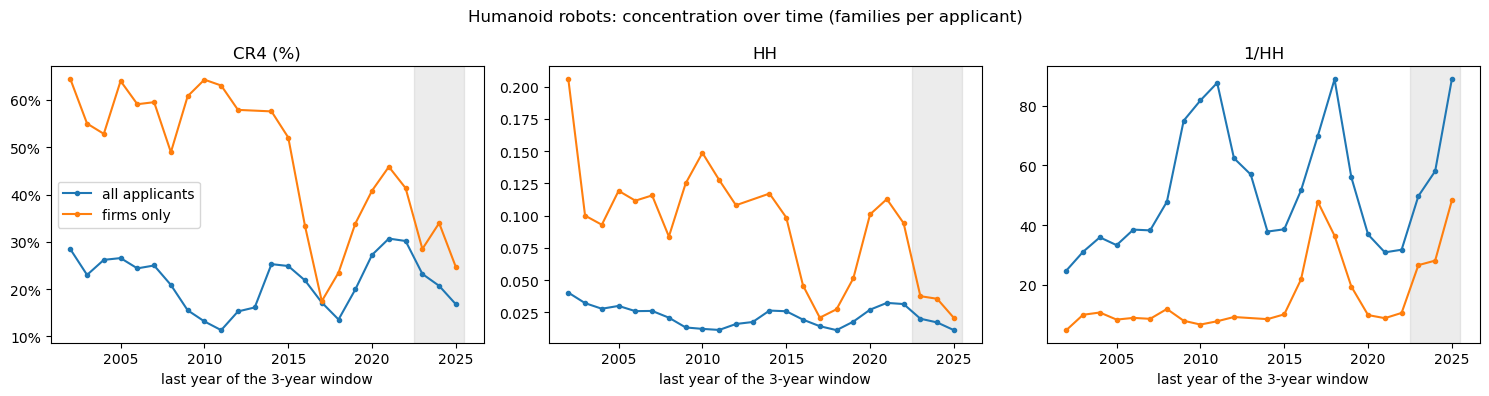

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ["CR4 (%)", "HH", "1/HH"]):
    for label, table in over_time.items():
        ax.plot(table.index, table[column], marker="o", ms=3, label=label)
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15)    # windows that end in an incomplete year
    ax.set(title=column, xlabel=f"last year of the {WINDOW}-year window")
axes[0].yaxis.set_major_formatter(PercentFormatter(100))
axes[0].legend()
fig.suptitle(f"{SECTOR_NAME}: concentration over time (families per applicant)")
plt.tight_layout()
plt.show()

**Do the measures agree?** The paper ranks its countries under each measure and compares the rankings with Kendall's tau-b: +1 for identical rankings, −1 for opposite ones, 0 for no relation (Section 4.8 of the original tutorial). We do the same on the time windows: the six measures on windows of `WINDOW` years that do not overlap (overlapping windows share years and would inflate the agreement), aligned on the last complete year. The row `year` shows each measure against time: a positive tau means that the measure sees the sector more concentrated as time goes by (consolidating), a negative one the opposite. If all the measures have the same sign, the conclusion on consolidation does not depend on the measure we choose. For Lotka, a slope close to 0 means more concentrated, so we flip its sign. The windows are few, so we read the signs and the size of tau, not a significance level.

In [16]:
# Do the measures agree? The paper ranks its countries under each measure and compares the rankings with Kendall's tau-b (Section 4.8 of the original tutorial).
# we compare time windows instead: the six measures on windows of WINDOW years that do not overlap (overlapping windows share years and would inflate the
# agreement), aligned on the last complete year, and Kendall's tau-b between each measure and the year.
MEASURES = ["CV", "CR4 (%)", "CR8 (%)", "HH", "Lotka L", "Gini"]
window_ends = [end for end in over_time["all applicants"].index
               if end <= LAST_COMPLETE_YEAR and (LAST_COMPLETE_YEAR - end) % WINDOW == 0]
by_window = pd.DataFrame({
    end: six_measures(links[links["year"].between(end - WINDOW + 1, end)].groupby("applicant")["unit_id"].nunique().to_numpy())
    for end in window_ends
}).T[MEASURES]
by_window["Lotka L"] = -by_window["Lotka L"].abs()           # as in the paper: L close to 0 means more concentrated; we flip it so that higher = more concentrated
by_window.insert(0, "year", by_window.index)

print(f"{len(by_window)} windows of {WINDOW} years, from {by_window.index.min() - WINDOW + 1} to {by_window.index.max()}")
by_window.corr(method="kendall").round(2)                       # Kendall's tau-b; a pair with a missing value is left out

7 windows of 3 years, from 2002 to 2022


,year,CV,CR4 (%),CR8 (%),HH,Lotka L,Gini
year,1.00,0.33,0.05,0.05,0.05,0.33,0.62
CV,0.33,1.00,0.52,0.52,0.52,1.00,0.71
CR4 (%),0.05,0.52,1.00,1.00,1.00,0.52,0.24
CR8 (%),0.05,0.52,1.00,1.00,1.00,0.52,0.24
HH,0.05,0.52,1.00,1.00,1.00,0.52,0.24
Lotka L,0.33,1.00,0.52,0.52,0.52,1.00,0.71
Gini,0.62,0.71,0.24,0.24,0.24,0.71,1.00


**Country by country.** The paper compares countries. We do the same for the countries of our applicants (families per applicant, complete years, all types of applicant), only for the countries with at least 40 applicants: with fewer, CR4 and CR8 are mechanically high and almost every applicant has a single family, so Gini and CV are close to 0 by construction. An applicant counts for one country (section 2.3), and a family with applicants of two countries counts for both: the families add up to more than the sector.

In [17]:
# The paper compares countries; here we compare the countries of our applicants (families per applicant, complete years)
country_of = links.drop_duplicates("applicant").set_index("applicant")["ctry"].reindex(families_per_applicant.index)
by_country = pd.DataFrame({
    country: six_measures(group.to_numpy())
    for country, group in families_per_applicant.groupby(country_of.to_numpy())
    if country and len(group) >= 40                               # fewer applicants: CR4 and CR8 are mechanically high, and almost every applicant has one family
}).T.rename(columns={"firms": "applicants", "patents (sum over firms)": "families (sum over applicants)"})
by_country.sort_values("families (sum over applicants)", ascending=False).round(3)

,applicants,families (sum over applicants),CV,CR4 (%),CR8 (%),HH,1/HH,Lotka L,Lotka p-value,Gini
CN,325.0,875.0,2.346,22.743,32.571,0.020,50.090,-1.194,0.000,0.553
JP,140.0,342.0,1.808,26.901,38.304,0.030,32.985,-1.192,0.000,0.505
KR,97.0,197.0,1.571,31.980,38.071,0.035,28.184,-1.348,0.002,0.432
US,62.0,115.0,0.742,20.000,33.913,0.025,40.198,-1.893,0.002,0.335


In [18]:
whole = six_measures(families_per_applicant.to_numpy())
complete_windows = table_windows[~table_windows["provisional"]]
first_w, last_w = complete_windows.index.min(), complete_windows.index.max()
ten_w = complete_windows.index[complete_windows.index <= last_w - 10].max()           # the window ten years before the last one
if pd.isna(ten_w):                                                                    # a shorter history: from the first window
    ten_w = first_w

def change(column, a, b):
    return f"{complete_windows.loc[a, column]:.3g} ({a}) to {complete_windows.loc[b, column]:.3g} ({b})"

hh_up = complete_windows.loc[last_w, "HH"] > complete_windows.loc[ten_w, "HH"]
cr4_up = complete_windows.loc[last_w, "CR4 (%)"] > complete_windows.loc[ten_w, "CR4 (%)"]
trend = "consolidating" if (hh_up and cr4_up) else "becoming less concentrated" if not (hh_up or cr4_up) else "showing no clear trend (HH and CR4 move in opposite directions)"

answer_box(
    "How concentrated is the field, and is it consolidating?",
    f"In the complete years {whole['firms']:,.0f} applicants share the families: the 4 largest hold {whole['CR4 (%)']:.0f}% (CR4), the Herfindahl index is "
    f"{whole['HH']:.3f}, as in a field of {whole['1/HH']:.0f} equal-sized applicants (1/HH), and the Gini coefficient is {whole['Gini']:.2f}. "
    f"Between the windows ending {ten_w} and {last_w} the field is {trend}.",
    f"Over those {WINDOW}-year windows HH goes from {change('HH', ten_w, last_w)}, CR4 (%) from {change('CR4 (%)', ten_w, last_w)}, "
    f"1/HH from {change('1/HH', ten_w, last_w)}. Read it with the table of windows: with few applicants HH is mechanically high.",
)

--------------------------------------------------------------------------------
ANSWER · How concentrated is the field, and is it consolidating?
In the complete years 724 applicants share the families: the 4 largest hold 12%
(CR4), the Herfindahl index is 0.008, as in a field of 133 equal-sized
applicants (1/HH), and the Gini coefficient is 0.50. Between the windows ending
2012 and 2022 the field is consolidating.
Over those 3-year windows HH goes from 0.016 (2012) to 0.0315 (2022), CR4 (%)
from 15.3 (2012) to 30.2 (2022), 1/HH from 62.4 (2012) to 31.8 (2022). Read it
with the table of windows: with few applicants HH is mechanically high.
--------------------------------------------------------------------------------


**Our reading of 5.1.** The field is fragmented, but it consolidated in the decade it stood still. In the complete years 724 applicants share the families: the four largest hold 12.5% (CR4), the Herfindahl index is 0.008 (as in a field of 133 applicants of equal size) and the Gini coefficient is 0.50. Among firms only (240) the field is more concentrated: CR4 27.3%, HH 0.027 (37 equal firms).    For small portfolios Lotka's law fits almost exactly (481, 117, 47 and 27 applicants with 1 to 4 families, against 481, 120, 53 and 30 predicted); the fitted slope (−1.44, flatter than the −2 of the law) comes from the tail: a few applicants with 40 to 94 families, far more than the law expects.

Over time, on 3-year windows, HH doubles from 0.016 (window ending 2012) to 0.031 (2022) and CR4 goes from 15.3% to 30.2%: fewer applicants account for more of the families, in the years when the sector does not grow (Step 1, Section 7.2). In the incomplete years the trend turns: hundreds of new applicants enter (439 active in 2025) and the window ending 2025 has a CR4 of 16.8%, provisional.

The measures do not tell the same story over the whole period. On 7 non-overlapping windows (2002–2022) Kendall's tau-b between the year and the measure is +0.62 for Gini and +0.33 for CV and Lotka (inequality among applicants rises), but only +0.05 for CR4, CR8 and HH (the share of the largest applicants has no trend over twenty years). So: no long-run consolidation of the top, a rising inequality, and a consolidation of the top in 2012–2022 only.

The names matter a little: from the PATSTAT names (A) to our brand key (C), CR4 rises from 9.4% to 10.7% and the equivalent number of applicants (1/HH) falls from 209 to 170; the coarse key (D) changes almost nothing. By country (at least 40 applicants), Korea (CR4 32.0% on 97 applicants) and Japan (26.9% on 140) are more concentrated than China (22.7% on 325) and the United States (20.0% on 62).

### 5.2 Question: who are the incumbents, and who are the new entrants?

**Top applicants.** The deck table: the largest applicants with their type and country, their families (all years), the year of their first family in the sector, and their status:

- **incumbent**: first family in the sector before `SPLIT_YEAR`;
- **entrant**: first family in the sector from `SPLIT_YEAR` on.

We keep SPLIT_YEAR = 2015, the value of the template: in Step 1 (Section 7.2) the sector grows from 36 families in 2012 to 93 in 2017, so 2015 separates the small first generation of players from the wave of the mid-2010s; the explosion of 2023–2025 falls inside the entrants' period. One limit: the rule of Step 0 needs a humanoid term in the title, so the Japanese incumbents, whose titles often say "legged mobile robot", are under-represented (Honda has 41 families in our sector). The status depends on this year, so it is a parameter: change it and the table follows.

The **profile** is the type of applicant, except for a firm whose first patent ever (in any field) is from `YOUNG_FIRM_YEAR` on, which we call a *young firm*: PATSTAT has no start-up type, so this is a proxy, and we check the largest applicants by hand for the deck. The applicant is the owner named on the patents, not the owner today (Boston Dynamics, for example, is kept apart from SoftBank and Hyundai: open question OQ-11 of Step 0).

In [19]:
by_applicant = links.groupby("applicant")
top_applicants = pd.DataFrame({
    "type": by_applicant["type"].first(),
    "country": by_applicant["ctry"].first(),
    "families": by_applicant["unit_id"].nunique(),
    f"families since {SPLIT_YEAR}": links[links["year"] >= SPLIT_YEAR].groupby("applicant")["unit_id"].nunique(),
    "first year in the sector": by_applicant["year"].min(),
    "last year in the sector": by_applicant["year"].max(),
    "first patent ever": first_ever,
}).fillna({f"families since {SPLIT_YEAR}": 0})
top_applicants["status"] = np.where(top_applicants["first year in the sector"] < SPLIT_YEAR, "incumbent", "entrant")
young = (top_applicants["type"] == "firm") & (top_applicants["first patent ever"] >= YOUNG_FIRM_YEAR)
top_applicants["profile"] = np.where(young, "young firm", top_applicants["type"])        # our proxy for a start-up
top_applicants = top_applicants.sort_values("families", ascending=False)

from_office = links.drop_duplicates("applicant").set_index("applicant")["country_from_office"]
print("Country taken from the office of first filing:",
      ", ".join(top_applicants.head(TOP_N).index[from_office.reindex(top_applicants.head(TOP_N).index).to_numpy()]) or "none of the top applicants")
top_applicants.head(TOP_N)

Country taken from the office of first filing: GUANGZHOU LIGONG INDUSTRIAL, BEIJING INSTITUTE OF TECHNOLOGY, SHENZHEN ZHUJI POWER TECHNOLOGY, HARBIN INSTITUTE OF TECHNOLOGY, HUAZHONG UNIVERSITY OF SCIENCE AND TECHNOLOGY, RENXING ROBOT SHANGHAI, SOUTH CHINA UNIVERSITY OF TECHNOLOGY, JIANGSU YUNMU ZHIZAO TECHNOLOGY


,type,country,families,families since 2015,first year in the sector,last year in the sector,first patent ever,status,profile
applicant,,,,,,,,,
UBTECH ROBOTICS,firm,CN,94,94.0,2016,2025,2015,entrant,young firm
GUANGZHOU LIGONG INDUSTRIAL,firm,CN,92,92.0,2024,2025,2004,entrant,firm
SHANGHAI FOURIER INTELLIGENT TECHNOLOGY,firm,CN,91,91.0,2023,2025,2016,entrant,young firm
BEIJING INSTITUTE OF TECHNOLOGY,university,CN,87,75.0,2008,2025,1988,incumbent,university
ZHEJIANG UNIVERSITY,university,CN,67,55.0,2008,2025,1985,incumbent,university
SHENZHEN ZHUJI POWER TECHNOLOGY,firm,CN,59,59.0,2023,2025,2021,entrant,young firm
HARBIN INSTITUTE OF TECHNOLOGY,university,CN,50,43.0,2008,2025,1985,incumbent,university
ZHEJIANG LAB,unknown,CN,46,46.0,2019,2024,2019,entrant,unknown
FIGURE AI,firm,US,44,44.0,2023,2024,2023,entrant,young firm


**Our reading of the top applicants.** Of the 15 largest applicants, 12 are Chinese; the others are Figure AI (United States), Honda (Japan) and Aldebaran / SoftBank Robotics Europe (France). Six are incumbents (Beijing Institute of Technology, Zhejiang University, Harbin Institute of Technology, South China University of Technology, Honda, Aldebaran) and nine are entrants, and six of the entrants filed their first family in the sector only in 2023–2025: Shanghai Fourier, Shenzhen Zhuji, Figure AI and Jiangsu Yunmu (2023), Guangzhou Ligong (2024) and Renxing Robot (2025). Six are young firms (first patent ever from 2010): UBTECH (2015), Shanghai Fourier (2016), Shenzhen Zhuji (2021), Jiangsu Yunmu (2022), Figure AI (2023) and Renxing Robot (2025). Guangzhou Ligong is different: an established firm (first patent in 2004) that enters the sector in 2024 with 92 families in two years. The old leader has stopped: Honda has 41 families (2000–2019), only one since 2015. The recent flow comes from young Chinese firms, from Chinese universities and from one US start-up.

One limit weighs on this table. The rule of Step 0 keeps a family only if its title names a humanoid robot, and several well-known players title their patents "legged robot" or just "robot": Boston Dynamics, Tesla, Unitree, Hyundai and 1X have no family in our sector, and Agility Robotics has one. The ranking is a ranking of humanoid-titled patenting, and it under-represents these players and the Japanese incumbents (Step 0, Section 6.8).

Notes on the names:
- Zhejiang Lab has no type in PATSTAT. It is a research institute funded by the Zhejiang provincial government, Zhejiang University and Alibaba, opened in September 2017 (China Daily); we read it as a research institute.
- Shenzhen Zhuji Power Technology is probably the company that sells humanoid, biped and wheeled-legged robots under the name LimX Dynamics (Pedaily). We did not find the legal name written in a source, so we treat it as a probable match, not a certain one.
- Aldebaran Robotics groups 8 names (31 families, 2008–2023): Aldebaran, SoftBank Robotics Europe (the same Paris company, renamed in 2016 and again Aldebaran from 2022, TechCrunch) and SoftBank Group, which shares the brand (Step 0, Section 7.2). The country is France.
- Players from the press, in the full list: Toyota 25 families (rank 17, 2002–2017), Samsung 24 (rank 18, 2002–2024), Disney 7 (rank 68), Apptronik 6 (rank 73, 2021–2024), Shanghai Zhiyuan Xinchuang 6 (rank 79, 2024–2025; probably AgiBot under its early legal name, not confirmed), Sanctuary 2, Google 2 (2015); Sony, Xiaomi and Agility Robotics have at most 2 families each. The client, Electrolux, has none. 

**Entry and exit, year by year.** For each year $t$:

- **active applicants**: applicants with at least one family in $t$;
- **new to the sector**: active applicants whose first family in the sector is in $t$;
- **new to patenting**: active applicants whose first patent ever, in any field, is in $t$ (“they never patented before”), from the lookup of Section 5.0;
- **entrants' share of families**: share of the families of $t$ with at least one applicant new to the sector; **new-to-patenting share of families**: the same for the applicants new to patenting;
- **rate of disappearance**: share of the applicants active in $t$ that never file again in the sector. It is shown only up to 3 years before the last complete year: an applicant silent in the last years may simply not be published yet.

In the first years of the window almost every applicant looks "new", because we do not see its families before `YEAR_MIN`, and the sector is very small: we show entry and exit from `PLOT_FROM`.

In [20]:
# Players we know from the press: where are they in our list? (rank among all applicants, families in the sector)
PRESS_PLAYERS = ["BOSTON DYNAMICS", "GOOGLE", "HYUNDAI", "TESLA", "AGILITY", "APPTRONIK", "UNITREE", "AGIBOT", "ZHIYUAN",
                 "XIAOMI", "SANCTUARY", "1X", "TOYOTA", "SAMSUNG", "SONY", "DISNEY", "ELECTROLUX"]
ranked = top_applicants.reset_index().rename(columns={"index": "applicant"})
ranked.insert(0, "rank", range(1, len(ranked) + 1))
hits = ranked[ranked["applicant"].str.contains("|".join(rf"\b{p}\b" for p in PRESS_PLAYERS), regex=True)]
hits[["rank", "applicant", "country", "families", "first year in the sector", "last year in the sector"]]

,rank,applicant,country,families,first year in the sector,last year in the sector
16,17,TOYOTA MOTOR,JP,25,2002,2017
17,18,SAMSUNG ELECT,KR,24,2002,2024
67,68,DISNEY ENTERPRISE,US,7,2011,2022
72,73,APPTRONIK,US,6,2021,2024
78,79,SHANGHAI ZHIYUAN XINCHUANG TECHNOLOGY,CN,6,2024,2025
298,299,SANCTUARY COGNITIVE SYSTEMS,CA,2,2022,2024
307,308,GOOGLE,US,2,2015,2015
350,351,SONY,JP,2,2000,2002
362,363,HANGZHOU ZHIYUAN RESEARCH INSTITUTE,CN,2,2025,2025
457,458,BEIJING XIAOMI ROBOT TECH,CN,2,2022,2022


In [21]:
first_year = by_applicant["year"].min()      # first family of each applicant in the sector
last_year = by_applicant["year"].max()       # last family of each applicant in the sector

active = links[["applicant", "year"]].drop_duplicates()
active["new to the sector"] = active["year"] == active["applicant"].map(first_year)
active["new to patenting"] = active["year"] == active["applicant"].map(first_ever)     # False where PATSTAT has no match
active["last family"] = active["year"] == active["applicant"].map(last_year)

entry_exit = active.groupby("year").agg(
    active_applicants=("applicant", "count"),
    new_to_the_sector=("new to the sector", "sum"),
    new_to_patenting=("new to patenting", "sum"),
    leaving=("last family", "sum"),
)
entry_exit["rate of disappearance (%)"] = entry_exit["leaving"] / entry_exit["active_applicants"] * 100
entry_exit.loc[entry_exit.index > LAST_COMPLETE_YEAR - 3, ["leaving", "rate of disappearance (%)"]] = np.nan   # an applicant silent in the last years may just not be published yet

# share of each year's families with at least one applicant new to the sector, and with at least one new to patenting
links_new = links.assign(new_sector=links["year"] == links["applicant"].map(first_year),
                         new_patenting=links["year"] == links["applicant"].map(first_ever))
share = links_new.groupby(["year", "unit_id"])[["new_sector", "new_patenting"]].any().groupby("year").mean() * 100
entry_exit["entrants' share of families (%)"] = share["new_sector"]
entry_exit["new-to-patenting share of families (%)"] = share["new_patenting"]
entry_exit.loc[PLOT_FROM:].round(1)

,active_applicants,new_to_the_sector,new_to_patenting,leaving,rate of disappearance (%),entrants' share of families (%),new-to-patenting share of families (%)
year,,,,,,,
2000,24,24,12,19.0,79.2,100.0,25.0
2001,16,13,3,6.0,37.5,86.7,26.7
2002,33,25,7,25.0,75.8,88.0,20.0
2003,18,12,3,7.0,38.9,78.3,13.0
2004,38,27,11,20.0,52.6,62.5,16.7
2005,39,22,8,27.0,69.2,40.9,18.2
2006,15,10,1,9.0,60.0,56.5,8.7
2007,37,24,9,23.0,62.2,50.0,16.7
2008,54,44,12,31.0,57.4,72.7,22.7


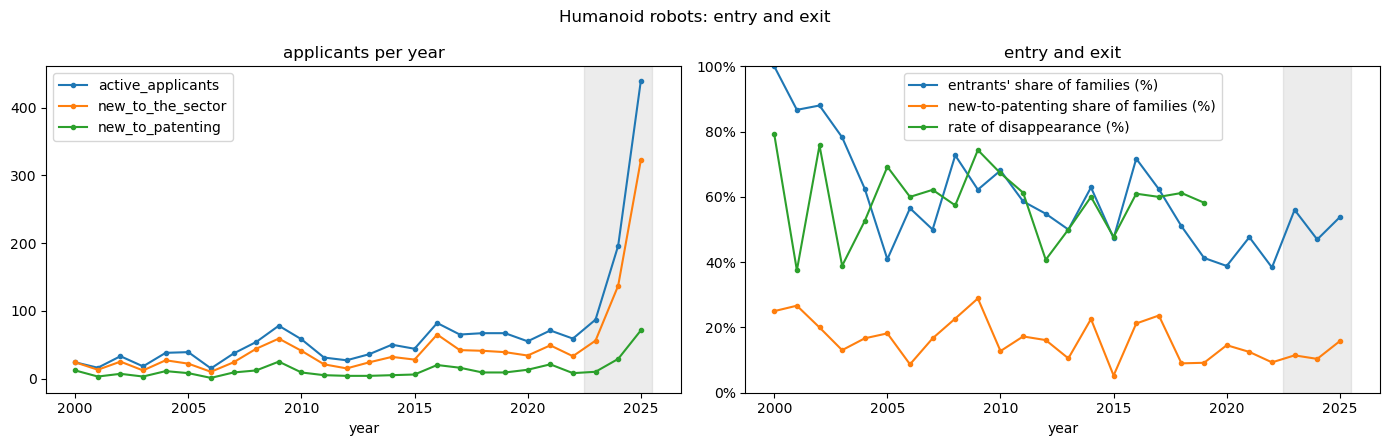

In [22]:
plot_table = entry_exit.loc[PLOT_FROM:]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_table[["active_applicants", "new_to_the_sector", "new_to_patenting"]].plot(ax=axes[0], marker="o", ms=3)
axes[0].set(title="applicants per year", xlabel="year")
plot_table[["entrants' share of families (%)", "new-to-patenting share of families (%)", "rate of disappearance (%)"]].plot(ax=axes[1], marker="o", ms=3)
axes[1].set(title="entry and exit", xlabel="year", ylim=(0, 100))
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
for ax in axes:
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15)   # incomplete years
fig.suptitle(f"{SECTOR_NAME}: entry and exit")
plt.tight_layout()
plt.show()

In [23]:
top = top_applicants.head(TOP_N)
incumbents = top[top["status"] == "incumbent"].index.tolist()
entrants = top[top["status"] == "entrant"].index.tolist()
young_firms = top[top["profile"] == "young firm"].index.tolist()
last5 = slice(LAST_COMPLETE_YEAR - 4, LAST_COMPLETE_YEAR)
recent_entry = entry_exit.loc[last5, "entrants' share of families (%)"].mean()
recent_new = entry_exit.loc[last5, "new-to-patenting share of families (%)"].mean()

answer_box(
    "Who are the incumbents, and who are the new entrants?",
    f"Among the {TOP_N} largest applicants, {len(incumbents)} are incumbents and {len(entrants)} are entrants. "
    f"Largest incumbents: {', '.join(incumbents[:3]) or 'none'}. Largest entrants (first family from {SPLIT_YEAR}): {', '.join(entrants[:3]) or 'none'}. "
    f"Young firms (first patent ever from {YOUNG_FIRM_YEAR}): {', '.join(young_firms) or 'none'}.",
    f"In the last five complete years, on average {recent_entry:.0f}% of each year's families had at least one applicant new to the sector "
    f"and {recent_new:.0f}% one that had never patented before.",
)

--------------------------------------------------------------------------------
ANSWER · Who are the incumbents, and who are the new entrants?
Among the 15 largest applicants, 6 are incumbents and 9 are entrants. Largest
incumbents: BEIJING INSTITUTE OF TECHNOLOGY, ZHEJIANG UNIVERSITY, HARBIN
INSTITUTE OF TECHNOLOGY. Largest entrants (first family from 2015): UBTECH
ROBOTICS, GUANGZHOU LIGONG INDUSTRIAL, SHANGHAI FOURIER INTELLIGENT TECHNOLOGY.
Young firms (first patent ever from 2010): UBTECH ROBOTICS, SHANGHAI FOURIER
INTELLIGENT TECHNOLOGY, SHENZHEN ZHUJI POWER TECHNOLOGY, FIGURE AI, RENXING
ROBOT SHANGHAI, JIANGSU YUNMU ZHIZAO TECHNOLOGY.
In the last five complete years, on average 43% of each year's families had at
least one applicant new to the sector and 11% one that had never patented
before.
--------------------------------------------------------------------------------


#### Who cites whom among the top applicants 

The balance between being cited and citing says how an applicant stands with respect to the others: balanced, it exchanges knowledge with them; strongly unbalanced, it mostly looks at the others (or is looked at) and may work in a different field or at a different moment. We measure it with the citations **between families of the sector** that Step 0 saved (`family_citations`), for the top applicants:

- **cites other applicants**: citations from its families to families of other applicants of the sector (each pair of families counts once);
- **cited by other applicants**: the opposite direction;
- **balance** = (cited − citing) / (cited + citing): +1 only cited, −1 only citing, 0 balanced.

Four limits. (1) A citation always goes from a later family to an earlier one, so a young applicant mostly cites and an old one is mostly cited: the balance also tells how old the applicant is (we show its first year). (2) We see only the citations inside our sector: two applicants that do not cite each other here may still cite each other outside it. (3) Part of the citations is added by the examiner, not by the applicant, and only the applicant's citations are a proxy of knowledge flows; the table saved in Step 0 does not keep the origin of the citation, so we cannot separate them. (4) Citation habits differ across offices (for example, US applicants must disclose all the prior art they know, so US filings carry more citations), and a family collects the citations of all its members: an applicant that files mostly in the US looks like it cites more. We do not correct for it. We read the table as a signal, not as a proof.

In [24]:
# Citations between the families of the sector. A family cites another when the second is in its list of cited documents;
# Step 0 saved each citation twice (backward from the citing family, forward from the cited one): we put them together and keep each pair once
edges = family_citations[["citing", "cited"]].drop_duplicates()     # Step 0 v2 saved each citation with its two families
in_set = set(families["docdb_family_id"])
edges = edges[edges["citing"].isin(in_set) & edges["cited"].isin(in_set) & (edges["citing"] != edges["cited"])]

# from families to applicants: every applicant of the citing family cites every applicant of the cited family
fam_applicant = links[["unit_id", "applicant"]].drop_duplicates()
flows = (edges.merge(fam_applicant.rename(columns={"unit_id": "citing", "applicant": "from"}), on="citing")
              .merge(fam_applicant.rename(columns={"unit_id": "cited", "applicant": "to"}), on="cited")
              .drop_duplicates(["citing", "cited", "from", "to"]))
own = flows[flows["from"] == flows["to"]].groupby("from").size()
flows = flows[flows["from"] != flows["to"]]

names_top = top_applicants.head(TOP_N).index
citing_others = flows.groupby("from").size().reindex(names_top).fillna(0)
cited_by_others = flows.groupby("to").size().reindex(names_top).fillna(0)
balance = pd.DataFrame({
    "cites its own families": own.reindex(names_top).fillna(0),
    "cites other applicants": citing_others,
    "cited by other applicants": cited_by_others,
})
balance["balance (cited - citing) / total"] = (cited_by_others - citing_others) / (cited_by_others + citing_others).replace(0, np.nan)
balance["first year in the sector"] = top_applicants.loc[names_top, "first year in the sector"]
print(f"{len(edges):,} citations between families of the sector; {flows[['citing', 'cited']].drop_duplicates().shape[0]:,} between different applicants")
balance.round(2)

2,750 citations between families of the sector; 2,381 between different applicants


,cites its own families,cites other applicants,cited by other applicants,balance (cited - citing) / total,first year in the sector
applicant,,,,,
UBTECH ROBOTICS,43.0,378,129,-0.49,2016
GUANGZHOU LIGONG INDUSTRIAL,29.0,46,5,-0.80,2024
SHANGHAI FOURIER INTELLIGENT TECHNOLOGY,61.0,130,33,-0.60,2023
BEIJING INSTITUTE OF TECHNOLOGY,36.0,226,176,-0.12,2008
ZHEJIANG UNIVERSITY,21.0,115,140,0.10,2008
SHENZHEN ZHUJI POWER TECHNOLOGY,35.0,53,21,-0.43,2023
HARBIN INSTITUTE OF TECHNOLOGY,9.0,51,80,0.22,2008
ZHEJIANG LAB,13.0,109,58,-0.31,2019
FIGURE AI,35.0,625,2,-0.99,2023


In [25]:
# The pairs of top applicants that exchange most citations, with the two directions
pairs = flows[flows["from"].isin(names_top) & flows["to"].isin(names_top)].groupby(["from", "to"]).size().rename("n").reset_index()
pairs = pairs.merge(pairs.rename(columns={"from": "to", "to": "from", "n": "n_back"}), on=["from", "to"], how="outer").fillna(0)
pairs = pairs[pairs["from"] < pairs["to"]].rename(columns={"from": "applicant A", "to": "applicant B", "n": "A cites B", "n_back": "B cites A"})
pairs["total"] = pairs["A cites B"] + pairs["B cites A"]
pairs["balance (A - B) / total"] = (pairs["A cites B"] - pairs["B cites A"]) / pairs["total"]
pairs.sort_values("total", ascending=False).head(10).round(2)

,applicant A,applicant B,A cites B,B cites A,total,balance (A - B) / total
17,BEIJING INSTITUTE OF TECHNOLOGY,ZHEJIANG UNIVERSITY,12.0,24.0,36.0,-0.33
15,BEIJING INSTITUTE OF TECHNOLOGY,UBTECH ROBOTICS,7.0,27.0,34.0,-0.59
95,UBTECH ROBOTICS,ZHEJIANG UNIVERSITY,17.0,5.0,22.0,0.55
16,BEIJING INSTITUTE OF TECHNOLOGY,ZHEJIANG LAB,5.0,12.0,17.0,-0.41
70,SHANGHAI FOURIER INTELLIGENT TECHNOLOGY,SHENZHEN ZHUJI POWER TECHNOLOGY,7.0,7.0,14.0,0.00
94,UBTECH ROBOTICS,ZHEJIANG LAB,4.0,9.0,13.0,-0.38
1,ALDEBARAN ROBOTICS,FIGURE AI,0.0,9.0,9.0,-1.00
52,HUAZHONG UNIVERSITY OF SCIENCE AND TECHNOLOGY,ZHEJIANG UNIVERSITY,7.0,0.0,7.0,1.00
23,GUANGZHOU LIGONG INDUSTRIAL,RENXING ROBOT SHANGHAI,6.0,1.0,7.0,0.71
44,HONDA MOTOR,UBTECH ROBOTICS,0.0,7.0,7.0,-1.00


**Our reading of the citations.** Among the top applicants Honda is the most cited relative to what it cites: 155 citations received from other applicants against 67 made (balance +0.40). South China University of Technology (+0.27), Harbin Institute of Technology (+0.22) and Zhejiang University (+0.10) are close to balanced. The young firms mostly cite: Figure AI (625 citations made, 2 received, −0.99), Guangzhou Ligong (−0.80), Jiangsu Yunmu (−0.69), Shanghai Fourier (−0.60), UBTECH (−0.49) and Shenzhen Zhuji (−0.43); limit (1) tells us that a part of this is only their age, and limit (4) applies to Figure AI, which files in the US. In the pairs, the Chinese universities and UBTECH form a cluster: Zhejiang University cites the Beijing Institute of Technology 24 times (12 the other way), UBTECH cites the Beijing Institute of Technology 27 times and Zhejiang University 17 times. Across countries, Figure AI cites Aldebaran 9 times and UBTECH cites Honda 7 times, never the other way. We read the table as a signal of who builds on whom, not as a proof.

### 5.3 Question: which subfields are growing fastest?

A **subfield** is a CPC group inside the sector. We take the technology symbols of the families (the CPC symbols that are not Y tags, which are cross-cutting labels) and cut each symbol at the first two digits after the slash: B25J9/1612 becomes B25J9/16. We check the titles of the groups in the CPC scheme before interpreting them (we do it for the fastest ones after the run).

We count the families of each subfield in two periods of 5 complete years and compare them. We keep only the subfields with at least `MIN_SUBFIELD` families in the later period, and we compute a growth rate only if the subfield had at least `MIN_PAST` families in the earlier one: from a base of one or two families, a growth of +1000% is just a few families more. The subfields from a smaller base are listed apart, without a rate. The incomplete years (after `LAST_COMPLETE_YEAR`) are left out. The dashed line of the figure is the growth of the whole sector: a subfield above it gains weight inside the sector, one below it loses weight even if it grows.
The label B62D57/03 is the group B62D57/032 cut at two digits: in our families no other symbol starts with B62D57/03.


In [26]:
RECENT = (LAST_COMPLETE_YEAR - 4, LAST_COMPLETE_YEAR)          # the last 5 complete years
PAST = (RECENT[0] - 5, RECENT[0] - 1)                          # the 5 years before


def subfield(cpc):
    "CPC group with the first two digits after the slash: B25J9/1612 -> B25J9/16."
    main_group, _, subgroup = cpc.partition("/")
    return f"{main_group}/{subgroup[:2]}"


# the technology symbols of the sector families (the Y tags are cross-cutting labels, not technologies), one row per family and subfield
# the technology symbols of the sector families: CPC without the Y tags (cross-cutting labels); the families without any
# CPC symbol (about 45% of those of 2010-2016, mostly filed only in Asia) take their IPC symbols, as in Step 1
cpc_symbols = family_cpc.loc[~family_cpc["is_tagging"], ["docdb_family_id", "cpc_symbol"]]
ipc_symbols = (family_ipc.loc[~family_ipc["docdb_family_id"].isin(cpc_symbols["docdb_family_id"]), ["docdb_family_id", "ipc_symbol"]]
               .rename(columns={"ipc_symbol": "cpc_symbol"}))
in_sector = pd.concat([cpc_symbols, ipc_symbols]).merge(families[["docdb_family_id", "priority_year"]], on="docdb_family_id")
in_sector["subfield"] = in_sector["cpc_symbol"].map(subfield)
in_sector = in_sector.drop_duplicates(["docdb_family_id", "subfield"])

past = in_sector[in_sector["priority_year"].between(*PAST)].groupby("subfield")["docdb_family_id"].nunique()
recent = in_sector[in_sector["priority_year"].between(*RECENT)].groupby("subfield")["docdb_family_id"].nunique()
subfields = pd.DataFrame({f"families {PAST[0]}-{PAST[1]}": past, f"families {RECENT[0]}-{RECENT[1]}": recent}).fillna(0)
subfields["growth (%)"] = (subfields.iloc[:, 1] / subfields.iloc[:, 0].where(subfields.iloc[:, 0] >= MIN_PAST) - 1) * 100      # NaN if the earlier period has fewer than MIN_PAST families
subfields = subfields[subfields.iloc[:, 1] >= MIN_SUBFIELD].sort_values(subfields.columns[1], ascending=False)

# the whole sector over the same two periods: a subfield above this growth gains weight inside the sector
sector_growth = (families["priority_year"].between(*RECENT).sum() / families["priority_year"].between(*PAST).sum() - 1) * 100
print(f"{len(subfields)} subfields with at least {MIN_SUBFIELD} families in {RECENT[0]}-{RECENT[1]}; the whole sector grows {sector_growth:.0f}% between the two periods")
small_base = subfields[subfields.iloc[:, 0] < MIN_PAST]
print(f"Without a growth rate (fewer than {MIN_PAST} families in {PAST[0]}-{PAST[1]}):",
      ", ".join(f"{name} ({row.iloc[0]:.0f} to {row.iloc[1]:.0f})" for name, row in small_base.iterrows()) or "none")
subfields.head(25).round(1)

17 subfields with at least 15 families in 2018-2022; the whole sector grows 43% between the two periods
Without a growth rate (fewer than 5 families in 2013-2017): none


,families 2013-2017,families 2018-2022,growth (%)
subfield,,,
B62D57/03,95.0,189.0,98.9
B25J9/16,75.0,137.0,82.7
B25J11/00,65.0,84.0,29.2
B25J9/00,41.0,47.0,14.6
G05D1/02,21.0,47.0,123.8
B25J19/00,34.0,44.0,29.4
B25J17/02,22.0,34.0,54.5
B25J9/10,14.0,28.0,100.0
B25J13/08,17.0,28.0,64.7


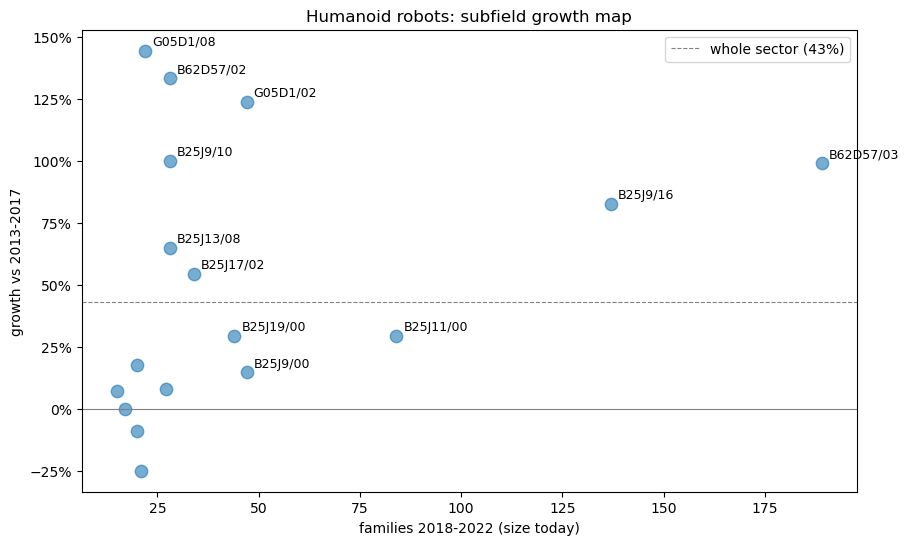

In [27]:
plot = subfields.dropna(subset=["growth (%)"])               # growth is defined only if the subfield had at least MIN_PAST families before                  
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(plot.iloc[:, 1], plot["growth (%)"], s=80, alpha=0.6)
label_these = set(plot.iloc[:, 1].nlargest(10).index) | set(plot["growth (%)"].nlargest(6).index)      # the biggest and the fastest
for name, row in plot.loc[sorted(label_these)].iterrows():
    ax.annotate(name, (row.iloc[1], row["growth (%)"]), xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.axhline(0, color="grey", lw=0.8)
ax.axhline(sector_growth, color="grey", lw=0.8, ls="--", label=f"whole sector ({sector_growth:.0f}%)")
ax.set(title=f"{SECTOR_NAME}: subfield growth map", xlabel=f"families {RECENT[0]}-{RECENT[1]} (size today)",
       ylabel=f"growth vs {PAST[0]}-{PAST[1]}")
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.legend()
plt.show()

In [28]:
fastest = plot.sort_values("growth (%)", ascending=False).head(3)

answer_box(
    "Which subfields are growing fastest?",
    ", ".join(f"{name} ({row['growth (%)']:+.0f}%)" for name, row in fastest.iterrows()),
    f"Growth of families from {PAST[0]}-{PAST[1]} to {RECENT[0]}-{RECENT[1]}, among the subfields with at least {MIN_SUBFIELD} families in the later period and at least {MIN_PAST} in the earlier one;  "
    f"the whole sector grows {sector_growth:.0f}%. Check the titles of these CPC groups in the CPC scheme.",
)

--------------------------------------------------------------------------------
ANSWER · Which subfields are growing fastest?
G05D1/08 (+144%), B62D57/02 (+133%), G05D1/02 (+124%)
Growth of families from 2013-2017 to 2018-2022, among the subfields with at
least 15 families in the later period and at least 5 in the earlier one;  the
whole sector grows 43%. Check the titles of these CPC groups in the CPC scheme.
--------------------------------------------------------------------------------


**Our reading of 5.3.** 17 subfields have at least 15 families in 2018–2022, and the whole sector grows 43% between the two periods. Titles from the CPC scheme:
- B62D 57/032, legged vehicles ("with alternately or sequentially lifted supporting base and legs"; label B62D57/03): the largest subfield, +99% (95 to 189 families);
- B62D 57/02, vehicles with ground-engaging propulsion means, e.g. walking members: +133% (12 to 28);
- B25J 9/16, programme controls of manipulators: +83% (75 to 137);
- G05D 1/02, control of position or course in two dimensions: +124% (21 to 47);
- G05D 1/08, control of attitude (roll, pitch, yaw): +144% (9 to 22);
- B25J 9/10, positioning means for manipulator elements: +100% (14 to 28).

The growth is in walking and balance: legs, and the control of position and attitude grow faster than the sector, while manipulation hardware grows slower or shrinks (B25J 17/00 +8%, B25J 13/00 0%, B25J 19/02 sensing devices −9%, B25J 5/00 manipulators on wheels or carriages −25%). G05D 1/02 and G05D 1/08 have been frozen since 1 January 2024 and their documents are being moved to new groups, so we read their growth with caution. The families without CPC take their IPC symbols (about 45% of those of 2010–2016), otherwise the earlier period would be undercounted and every growth rate inflated.

Top right: large and growing subfields; top left: small but growing fast; bottom: declining subfields. Topics extracted from abstracts are another way to define subfields: they are the subject of Landscaping tutorial 2 (patent text).

**PEST analysis: humanoid robots and Electrolux.** The first three columns are facts, each with the number of its source (list below). The last column is our reading for Electrolux, a maker of household appliances, and the priority (high, medium, low) is our judgement: high when the factor can change whether, when or how Electrolux enters the field. We checked dates and figures on 2 November 2026.

| Force | Factor and evidence | Effect on the field | Opportunity or threat for Electrolux (priority) |
|---|---|---|---|
| Political | China puts robotics "at the heart of its modern industrial system" in the 15th Five-Year Plan (2026-2030) and sees the commercialisation of humanoid robots "rather towards the end of the plan's period" [1]. In July 2026 the MIIT committee for humanoid and embodied-intelligence standards describes a move "from single-unit prototypes and stage demonstrations toward batch deliveries" and sets up a data working group [2]. | Chinese applicants hold 65% of the families of the complete years (Step 1, Section 9.2): state support and national standards favour them, and they set the first rules products must meet. | Threat: state-backed Chinese makers can scale and cut prices faster than a European group. Opportunity: standards written now can be followed or joined. Priority: medium (the plan itself puts commercialisation late). |
| Political | The EU Machinery Regulation 2023/1230 applies from 20 January 2027; its Annex I, the list of high-risk machinery with enhanced conformity assessment, now includes safety components "with fully or partially self-evolving behaviour using machine learning approaches" [3]. The Digital Omnibus on AI, in force since 27 July 2026, moves the AI Act high-risk dates to 2 December 2027 (stand-alone systems) and 2 August 2028 (AI in regulated products), and takes AI in machinery out of the AI Act's direct scope: the Commission can add AI safety requirements through the Machinery Regulation [4]. | A humanoid robot sold in the EU from 2027 must be shown safe under the new rules (if it counts as machinery: our reading); the AI-specific requirements are still to be written. | Threat: compliance cost and a rulebook that is not final. Opportunity: a group used to product safety in the home can turn this into an advantage over entrants. Priority: high. |
| Economic | Money goes to few players: Figure AI raised more than USD 1 billion at a USD 39 billion valuation (September 2025) [5]; Apptronik reopened its Series A to USD 935 million, at about USD 5.3 billion post-money (February 2026; the valuation is TechCrunch's report, the company did not disclose it) [6]; Unitree priced its Shanghai STAR Market IPO on 6 August 2026 at a valuation of about USD 9 billion [7]. | These players can fund R&D for years. Money and patenting grow together (the sector's share of the robotics families rises from 4.9 per 1,000 in 2022 to 25 in 2024 and 56 in 2025, incomplete years, Step 1 Section 7.2); we do not claim that one causes the other. | Threat: well-funded entrants with a head start. Opportunity: partnership, supply or investment instead of building from zero. Priority: high. |
| Economic | List prices reported in September 2025: Unitree R1 from the equivalent of USD 5,900, G1 USD 13,800 [8]. Goldman Sachs raised its 2035 forecast to about 6.5 million humanoid shipments, worth about USD 138 billion (1.38 million before); the source notes that it is a forecast and not an order book [9]. | A humanoid can cost thousands, not tens of thousands, of dollars. The volumes of 2035 are a scenario, not orders. | Opportunity: a price that starts to look like a durable good. Threat: relying on the forecast would overstate demand, so we use it only as a scenario. Priority: medium. |
| Social | Ageing: in the EU 22.0% of the population is 65 or over and the old-age dependency ratio is 34.5% (1 January 2025); it is projected to reach 59.7% by 2100 [10]. | Fewer people of working age for each older person: more need for help at home and for labour (our inference: Eurostat gives the demographic figures only). | Opportunity: help at home is the use closest to Electrolux's household customers. Priority: medium (long term). |
| Social | Acceptance and privacy: on 30 October 2025 1X announced its NEO home robot at USD 20,000 or USD 499 a month, with first deliveries to homes in the US in 2026 and other markets from 2027. For chores it has not learned, owners can schedule a 1X teleoperator to guide it; it has "no go" zones and can blur the faces of the people it meets [11]. | A robot at home sees inside the home: who can control it remotely, and what happens to the data, become part of the purchase decision. | Threat: buyers' trust is not given to a new entrant. Opportunity: a brand already trusted in the home could be an advantage (our reading, not shown by data). Priority: medium. |
| Technological | Google DeepMind presented Gemini Robotics 2 on 30 July 2026: a vision-language-action model "capable of controlling full humanoids, from feet to fingertips", shown on Apptronik's Apollo 2, with Apptronik, Boston Dynamics and Agile Robots thanked as partners. The same post says "multi-finger dexterous manipulation remains challenging" (36% success in screwing a bulb, in one of its benchmarks); the models are open to early-access partners only [12]. | A general model for the "brain" is becoming something robot makers can use rather than build; the hand and fine manipulation remain the bottleneck. | Opportunity: no need to develop the AI layer from zero. Threat: dexterity is not solved, so the timing is uncertain. Priority: high. |
| Technological | Our own data: only 8.4% of the families of 2017-2022 have a computing or AI class (G06, G10L), and universities hold 47.3% of the families of the same period, fractional counting (Step 1, Section 10.1). | The patents show the hardware and the academic work better than the learning and control software, which firms often keep secret or protect with copyright (our proxy of Step 1). | A limit of this report more than a threat: the patent landscape under-represents the software of the field. Priority: not applicable. |

**Sources** (all accessed on 2 November 2026)

1. International Federation of Robotics, press release "China makes AI-powered robots core of national strategy", 5 May 2026. https://ifr.org/ifr-press-releases/news/china-makes-ai-powered-robots-core-of-national-strategy
2. China Daily (Invest in China), Ma Si, "Nation sets standards to propel humanoid robot industry toward mass production", 21 July 2026. https://investinchina.chinadaily.com.cn/s/202607/21/WS6a5f11ed498e23165e07129e/nation-sets-standards-to-propel-humanoid-robot-industry-toward-mass-production.html
3. Baker McKenzie, Product Risk Radar, page on the Machinery Regulation (no date on the page). https://www.bakermckenzie.com/en/insight/publications/resources/product-risk-radar-articles/machinery-regulation
4. Lewis Silkin, "The Digital Omnibus on AI enters into force today", 27 July 2026. https://www.lewissilkin.com/insights/2026/07/27/the-digital-omnibus-on-ai-enters-into-force-today
5. Bloomberg News (via Bloomberg Tax), article on Figure AI valued at USD 39 billion, 16 September 2025. https://news.bloombergtax.com/private-equity/robotics-startup-figure-ai-valued-at-39-billion-in-new-funding
6. TechCrunch, article on Apptronik's Series A extension, 11 February 2026. https://techcrunch.com/2026/02/11/humanoid-robot-startup-apptronik-has-now-raised-935m-at-a-5b-valuation/
7. Yicai Global, article on Unitree's Shanghai IPO, 7 August 2026. https://www.yicaiglobal.com/news/unitree-robotics-to-raise-usd843-million-in-shanghai-ipo
8. AI Business, Graham Hope, article on Unitree's IPO plans and prices, 10 September 2025. https://aibusiness.com/robotics/humanoid-robot-company-valued-at-7b-as-it-eyes-ipo
9. Humanoid.guide, "Goldman raises 2035 humanoid robot forecast to 6.5 million", 15 September 2026 (secondary source: it cites 24/7 Wall St. and GuruFocus; we did not read the Goldman report). https://humanoid.guide/goldman-raises-2035-humanoid-robot-forecast-to-6-5-million/
10. Eurostat, Statistics Explained, "Population structure and ageing" (data at 1 January 2025). https://ec.europa.eu/eurostat/statistics-explained/index.php/Population_structure_and_ageing
11. The Robot Report, Mike Oitzman, article on the 1X NEO pre-order launch, 30 October 2025. https://www.therobotreport.com/1x-announces-pre-order-launch-neo-humanoid-robot/
12. Google DeepMind, Carolina Parada, "Gemini Robotics 2 brings whole-body intelligence to robots", 30 July 2026. https://deepmind.google/blog/gemini-robotics-2-brings-whole-body-intelligence-to-robots/

---

← [10 · Patent attributes](10_patent_attributes.ipynb) &nbsp;|&nbsp; [Back to the README](../README.md)